In [ ]:
import pandas as pd
import numpy as np
import pickle
import sys
import matplotlib.pyplot as plt
import pickle
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = 'glpk'

In [ ]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

gem2seed = pd.read_csv('../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')
Ecoli = cobra.io.load_json_model('../../Expression_datasets/palsson_nc/iML1515.json')

In [4]:
Ecoli_gpr = []
for rec in Ecoli.reactions:

    seedrec = rec.annotation.get('seed.reaction')
    if seedrec is None:
        continue

    seedrec = seedrec[0]

    if len(rec.genes) > 0:
        gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
        Ecoli_gpr.append((seedrec, gene_id))
Ecoli_gpr = pd.DataFrame(Ecoli_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])

In [5]:
cluster_genes = {}
for idx, group in cluster_nodes.items():
    for rec in group:
        rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
        rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
        if rec2seed is not None:
            rec2gene = Ecoli_gpr[Ecoli_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
            rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
            if rec2gene is not None:
                if idx not in cluster_genes:
                    cluster_genes[idx] = []
                for gene in rec2gene:
                    cluster_genes[idx].append(gene)

In [6]:
Ecoli_trans_data = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Expression Data')
gr = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['Growth Rate (1/hr)']
pH = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['pH']
antibiotic = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['Antibiotic']
gene_classification = pd.read_excel('../../Expression_datasets/hwa_pnas/gene_classification.xlsx', sheet_name='Ecoli')

In [7]:
# index = (gr.notna()) & (gr > 0.0)
index = (gr.notna()) & (gr > 0.2) & (gr < 1.3) & (pH == 7) & (antibiotic.isna())
gr = gr[index]
id_col = Ecoli_trans_data.iloc[:, 0]
Ecoli_tpm = 2 ** Ecoli_trans_data.iloc[:, 1:] - 1
Ecoli_trans_data = Ecoli_tpm / Ecoli_tpm.sum(axis=0)
Ecoli_trans_data = Ecoli_trans_data.loc[:, index.values]
Ecoli_trans_data = pd.concat([id_col, Ecoli_trans_data], axis=1)

In [ ]:
n_samples = Ecoli_trans_data.shape[1] - 1
overall_value = np.zeros((len(cluster_nodes), n_samples)) 

for idx, group in cluster_genes.items():

    group_value = np.zeros(n_samples)

    for gene in group:
        gene_count = sum(gene in g for g in cluster_genes.values())

        gene_value = Ecoli_trans_data[Ecoli_trans_data['log-TPM'] == gene].iloc[:, 1:].values

        if gene_value.size == 0:
            continue

        gene_value = np.array(gene_value[0]) / gene_count

        group_value += gene_value

    overall_value[idx, :] = group_value

norm_overall_value = overall_value / np.sum(overall_value, axis=0)

In [ ]:
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float

with open('../../FBAsolution/all_samples.pkl', 'rb') as f:
    data = pickle.load(f)
samples1 = data['samples1']
samples2 = data['samples2']
samples3 = data['samples3']
samples4 = data['samples4']
samples = samples1[:202] + samples2[:202] + samples3[:202] + samples4

In [ ]:
# pip install gurobipy
# If Gurobi license is not available, can solve the MIQP problem using other solvers like CPLEX or CBC, but the code below is specifically designed for Gurobi.
from __future__ import annotations
import numpy as np
from gurobipy import Model, GRB, QuadExpr, quicksum

def fit_miqp_signed_A(
    E_list,
    Y, 
    drop_idx=None,
    symmetric=False,  
    include_diag=False,
    mask=None,
    K=None, 
    scaling_factor=1.0, 
    ridge_c=1e-3, 
    ridge_A=1e-4, 
    time_limit=None, 
    mip_gap=None, 
    threads=None 
):
    m = len(E_list)
    n_full = E_list[0].size
    keep = np.ones(n_full, dtype=bool)
    if drop_idx:
        keep[drop_idx] = False
    idx = np.where(keep)[0]
    n = idx.size

    E = np.stack([e[idx] for e in E_list], axis=0)   # (m, n)

    if mask is None:
        mask_c = np.ones((n, n), dtype=int)
    else:
        mask_c = mask[np.ix_(idx, idx)].astype(int)

    pair_index = []
    if symmetric:
        for i in range(n):
            j_start = i if include_diag else i+1
            for j in range(j_start, n):
                if mask_c[i, j] != 0:
                    pair_index.append((i, j))
    else:
        for i in range(n):
            for j in range(n):
                if (include_diag or i != j) and mask_c[i, j] != 0:
                    pair_index.append((i, j))

    W = {}
    for s in range(m):
        Ei = E[s]
        if symmetric:
            for (i, j) in pair_index:
                if i == j:
                    W[(s, i, j)] = Ei[i] * Ei[j]
                else:
                    W[(s, i, j)] = 2.0 * Ei[i] * Ei[j]
        else:
            for (i, j) in pair_index:
                W[(s, i, j)] = Ei[i] * Ei[j]

    mdl = Model("signed_A_no_intercept")

    if time_limit is not None:
        mdl.setParam(GRB.Param.TimeLimit, time_limit)
    if mip_gap is not None:
        mdl.setParam(GRB.Param.MIPGap, mip_gap)
    if threads is not None:
        mdl.setParam(GRB.Param.Threads, threads)

  
    c = mdl.addVars(n, vtype=GRB.CONTINUOUS, lb=-GRB.INFINITY, name="c")

  
    A = {}
    for (i, j) in pair_index:
        lb, ub = (-1, 1)
        if mask_c[i, j] == 0:
            lb = ub = 0
        A[(i, j)] = mdl.addVar(vtype=GRB.INTEGER, lb=lb, ub=ub, name=f"A[{i},{j}]")

    if K is not None:
        z = mdl.addVars(len(pair_index), vtype=GRB.BINARY, name="z")
        for k, (i, j) in enumerate(pair_index):
            mdl.addConstr(A[(i, j)] <= z[k],  name=f"card_pos[{i},{j}]")
            mdl.addConstr(-A[(i, j)] <= z[k], name=f"card_neg[{i},{j}]")
        mdl.addConstr(z.sum() <= K, name="cardinality")


    obj = QuadExpr()
    for s in range(m):
        lin = quicksum(c[i] * E[s, i] for i in range(n))
        inter = quicksum(scaling_factor * A[(i, j)] * W[(s, i, j)] for (i, j) in pair_index)
        resid = (Y[s] - lin - inter)   # 无截距
        obj += resid * resid
    if ridge_c and ridge_c > 0:
        obj += ridge_c * quicksum(c[i] * c[i] for i in range(n))
    if ridge_A and ridge_A > 0:
        obj += ridge_A * quicksum(A[(i, j)] * A[(i, j)] for (i, j) in pair_index)

    mdl.setObjective(obj, GRB.MINIMIZE)
    mdl.optimize()

    c_sol = np.zeros(n) if mdl.status == GRB.OPTIMAL or mdl.status == GRB.TIME_LIMIT else None
    A_sol = np.zeros((n, n), dtype=int) if c_sol is not None else None

    if c_sol is not None:
        for i in range(n):
            c_sol[i] = c[i].X

        for (i, j) in pair_index:
            val = int(round(A[(i, j)].X))
            if symmetric:
                A_sol[i, j] = scaling_factor * val
                if i != j:
                    A_sol[j, i] = scaling_factor * val
            else:
                A_sol[i, j] = scaling_factor * val

        c_full = np.zeros(n_full)
        A_full = np.zeros((n_full, n_full), dtype=int)
        c_full[idx] = c_sol
        A_full[np.ix_(idx, idx)] = A_sol

        return {
            "status": int(mdl.status),
            "obj": float(mdl.objVal) if mdl.SolCount > 0 else None,
            "c": c_full,
            "A": A_full,
            "pair_count": len(pair_index),
            "gap": mdl.MIPGap if mdl.SolCount > 0 and hasattr(mdl, "MIPGap") else None
        }
    else:
        return {"status": int(mdl.status), "obj": None, "c": None, "A": None, "pair_count": len(pair_index)}

def predict_no_intercept(E_vec: np.ndarray, c: np.ndarray, A: np.ndarray) -> float:
    return float(E_vec @ c + E_vec @ A @ E_vec)


In [ ]:
def train_model_w_A(training_x, training_y, scaling_factor=1.0, K=None, mask=None):

    out = fit_miqp_signed_A(
        training_x, training_y,
        drop_idx=[19],
        symmetric=True,
        include_diag=False,
        mask=mask,
        K=K,
        scaling_factor=scaling_factor,
        ridge_c=1e-3,
        ridge_A=1e-4,
        time_limit=600,
        mip_gap=0.01,
        threads=0 
    )

    return out

In [ ]:
from scipy.stats import linregress
from scipy.stats import spearmanr


def aic(model, n, rss):
    k = np.count_nonzero(model['A']) + 19
    return n * np.log(rss / n + 1e-15) + 2 * k

training_set = samples
training_x = [s.E for s in samples]
Y = np.array([s.Y for s in samples], float)
training_y = Y

testing_x = np.array(norm_overall_value, dtype=float)
Y = np.array(gr, dtype=float)
testing_y = Y


total_aic = []
total_corr = []
total_palsson_r = []
total_palsson_corr = []

testing_y_pred_0 = []
testing_y_0 = []

testing_y_pred_30 = []
testing_y_30 = []

F = np.arange(0, 100, 2)



for factor in [0, 30]:
    predict_model = train_model_w_A(training_x, training_y, scaling_factor=factor, K=None, mask=None)
    Y_true = training_y
    Y_pred = np.array([predict_no_intercept(e, predict_model['c'], predict_model['A']) for e in training_x])
    rss = np.sum((Y_true - Y_pred)**2)

    

    testing_y_pred = np.array([predict_no_intercept(e, predict_model['c'], predict_model['A']) for e in testing_x.T])

    if factor == 0:
        testing_y_pred_0 = testing_y_pred
        testing_y_0 = testing_y
    if factor == 30:
        testing_y_pred_30 = testing_y_pred
        testing_y_30 = testing_y

    total_corr.append(spearmanr(Y_true, Y_pred).correlation)

    # total_palsson_corr.append(spearmanr(testing_y_pred, testing_y).correlation)

    # total_palsson_r.append(linregress(testing_y_pred, testing_y).rvalue)

    total_aic.append(aic(predict_model, len(training_set), rss))

Set parameter TimeLimit to value 600
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (linux64 - "Ubuntu 22.04.4 LTS")

CPU model: 12th Gen Intel(R) Core(TM) i5-12600KF, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 0 rows, 190 columns and 0 nonzeros
Model fingerprint: 0x115e62c2
Model has 361 quadratic objective terms
Variable types: 19 continuous, 171 integer (0 binary)
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  Objective range  [4e+00, 8e+02]
  QObjective range [2e-04, 2e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [0e+00, 0e+00]
Found heuristic solution: objective 2776.7120814
Presolve removed 0 rows and 171 columns
Presolve time: 0.01s
Presolved: 0 rows, 19 columns, 0 nonzeros
Presolved model has 190 quadratic objective terms
Found heuristic solution: objective 2776.6949814
Variable types: 19 continuous, 0 integer (0 binary)
Root r

Factor=0: LinregressResult(slope=0.04120038131581551, intercept=1.3928563440628903, rvalue=0.08672909385088955, pvalue=0.3246223189732348, stderr=0.04166793997506702, intercept_stderr=0.027411315937042744)
Factor=30: LinregressResult(slope=0.6926149175709585, intercept=0.6818338449640735, rvalue=0.5447243848366143, pvalue=1.7445327128969315e-11, stderr=0.09388211501636458, intercept_stderr=0.06176048820966976)


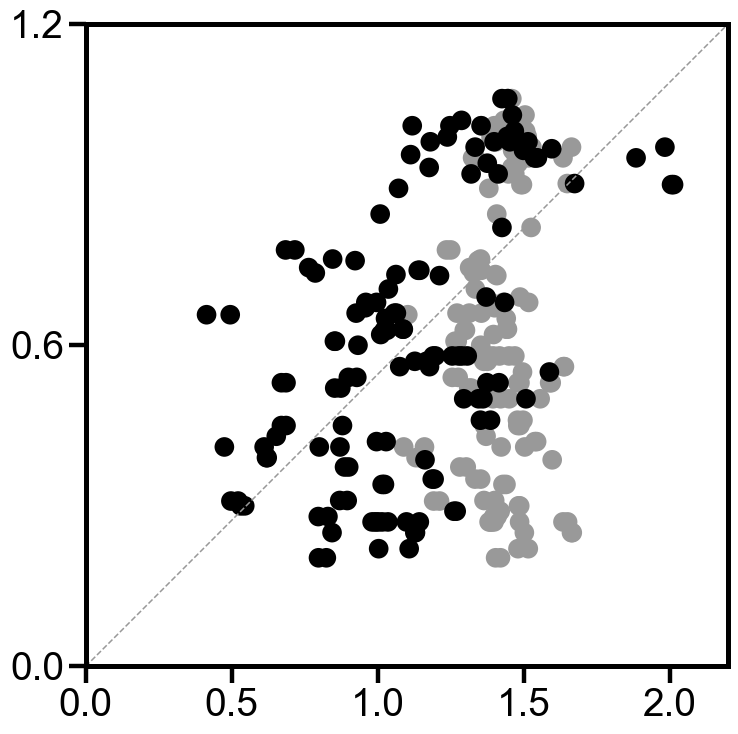

In [ ]:
set_panel_style(scale=4)

fig, ax = plt.subplots(figsize=(8, 8))


ax.scatter(
    testing_y_pred_0, testing_y_0,
    s=200,
    color=(0.6, 0.6, 0.6),
    edgecolors="none",
    alpha=1
)

ax.scatter(
    testing_y_pred_30, testing_y_30,
    s=200,
    color=(0, 0, 0),
    edgecolors="none",
    alpha=1
)

k_inv = 1.2/2.2

xmin = float(np.nanmin(testing_y_pred))
xmax = float(np.nanmax(testing_y_pred))

ymin = float(np.nanmin(testing_y))
ymax = float(np.nanmax(testing_y))

ax.set_ylim(0, 1.2)
ax.set_xlim(0, 2.2)
ax.set_yticks(np.arange(0, 1.21, 0.6))

xx = np.linspace(*ax.get_xlim(), 200)
ax.plot(xx, k_inv * xx, linestyle="--", color=(0.6, 0.6, 0.6), linewidth=1.1, alpha=1)

ax.set_box_aspect(1)
print("Factor=0:", linregress(testing_y_0, testing_y_pred_0))
print("Factor=30:", linregress(testing_y_30, testing_y_pred_30))
plt.tight_layout()
plt.show()

In [18]:
total_aic

[-1196.717658873114, -1313.0746201400723]